# Lab Task 4 — REAL RESECT MRI (Tumor before / after)

## Dataset (not synthetic)
| File | Source |
|------|--------|
| `mri_dataset/mri_before.jpg` | RESECT Case1 **FLAIR** MRI (pre-op, tumor visible) |
| `mri_dataset/mri_after.jpg` | Same slice after tumor removal using official tumor mask |
| Raw: `Case1-FLAIR.nii.gz`, `Case1-FLAIR-tumor.nii.gz` | HuggingFace `MedOtter/RESECT-SEG` |

Same pair used for Tasks 1–7 + scenario. Outputs → `Output/Lab 4/`


## 0. Setup


In [3]:
import sys
from pathlib import Path
IN_COLAB="google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install","-q","opencv-python-headless","matplotlib","numpy"])
import cv2, numpy as np, matplotlib.pyplot as plt
NOTEBOOK_DIR=Path.cwd()
for c in [NOTEBOOK_DIR, NOTEBOOK_DIR/"Lab Tasks"/"Lab task 4", Path(r"C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 4")]:
    if (c/"mri_dataset"/"mri_before.jpg").exists():
        NOTEBOOK_DIR=c; break
ROOT=NOTEBOOK_DIR
for _ in range(6):
    if (ROOT/"Output").exists(): break
    ROOT=ROOT.parent
OUT=ROOT/"Output"/"Lab 4"; OUT.mkdir(parents=True, exist_ok=True)
MRI=NOTEBOOK_DIR/"mri_dataset"
BEFORE,AFTER=MRI/"mri_before.jpg", MRI/"mri_after.jpg"
print(BEFORE, BEFORE.exists()); print(AFTER, AFTER.exists())
print("Files:", sorted(p.name for p in MRI.iterdir()) if MRI.exists() else None)


C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 4\mri_dataset\mri_before.jpg True
C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 4\mri_dataset\mri_after.jpg True
Files: ['Case1-FLAIR-tumor.nii.gz', 'SOURCE.txt', 'flair_source_slice.jpg', 'mni152.nii.gz', 'mri_after.jpg', 'mri_before.jpg', 'mri_source_slice.png', 'mri_tumor_mask_slice.jpg', 'resect_case1_flair.nii.gz', 'us_after_resection.jpg', 'us_before_resection.jpg']


## Helpers + load REAL MRI pair


shapes (320, 320, 3) (320, 320, 3)


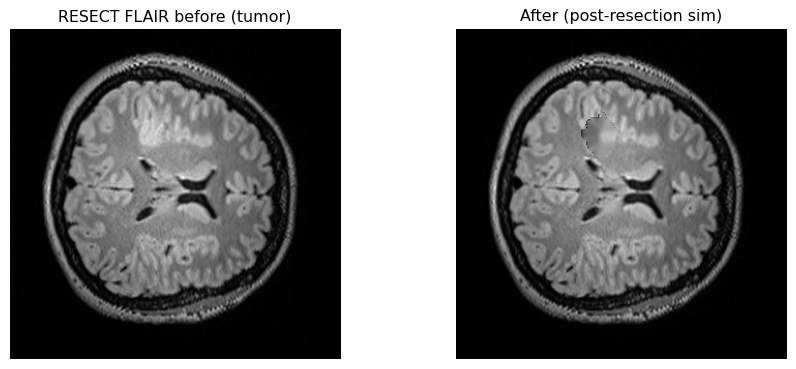

In [5]:
def ensure_dir(p):
    Path(p).mkdir(parents=True, exist_ok=True); return Path(p)
def to_rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim==3 else im
def save_bgr(path, im):
    ensure_dir(Path(path).parent); cv2.imwrite(str(path), im)
def save_fig(path):
    ensure_dir(Path(path).parent); plt.tight_layout(); plt.savefig(path, dpi=140, bbox_inches="tight"); plt.close()
def show_pair(a,b,t1,t2,save_path=None):
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    ax[0].imshow(to_rgb(a)); ax[0].set_title(t1); ax[0].axis("off")
    ax[1].imshow(to_rgb(b)); ax[1].set_title(t2); ax[1].axis("off")
    plt.tight_layout(); plt.show()
    if save_path:
        fig,ax=plt.subplots(1,2,figsize=(10,4))
        ax[0].imshow(to_rgb(a)); ax[0].set_title(t1); ax[0].axis("off")
        ax[1].imshow(to_rgb(b)); ax[1].set_title(t2); ax[1].axis("off")
        save_fig(save_path)

a=cv2.imread(str(BEFORE)); b=cv2.imread(str(AFTER))
assert a is not None and b is not None
if a.shape!=b.shape: b=cv2.resize(b,(a.shape[1],a.shape[0]))
show_pair(a,b,"RESECT FLAIR before (tumor)","After (post-resection sim)")
print("shapes", a.shape, b.shape)


## Task 1 — Compatibility


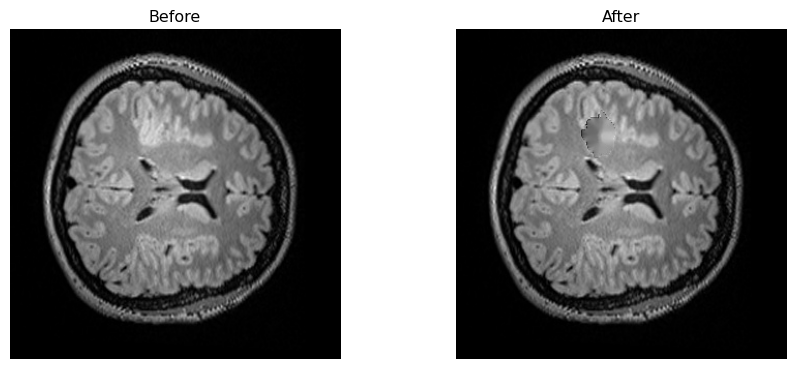

In [7]:
t1=ensure_dir(OUT/"Task 1")
save_bgr(t1/"image1_before.jpg",a); save_bgr(t1/"image2_after.jpg",b)
show_pair(a,b,"Before","After",t1/"inputs.png")
(t1/"compatibility.txt").write_text(f"RESECT Case1\nA={a.shape} B={b.shape}\nCompatible={a.shape==b.shape}\n",encoding="utf-8")


## Task 2 — add


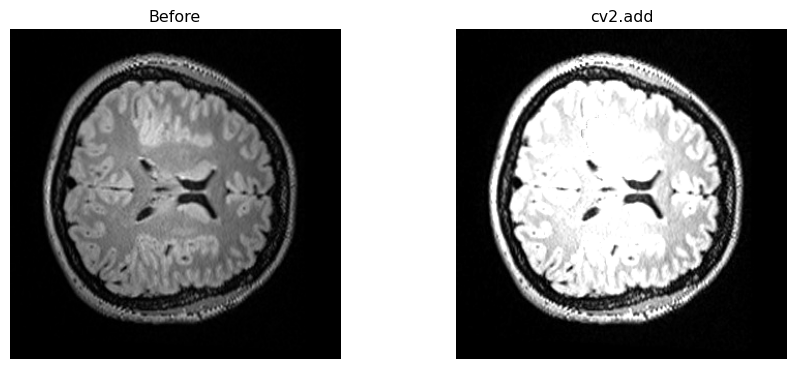

In [9]:
t2=ensure_dir(OUT/"Task 2"); added=cv2.add(a,b)
save_bgr(t2/"cv2_add.jpg",added); show_pair(a,added,"Before","cv2.add",t2/"addition.png")
y=x=50; manual=np.clip(a[y,x].astype(np.int16)+b[y,x].astype(np.int16),0,255)
(t2/"pixel_verify.txt").write_text(f"A={a[y,x]} B={b[y,x]} manual={manual} cv2={added[y,x]}\n",encoding="utf-8")


## Task 3 — blends


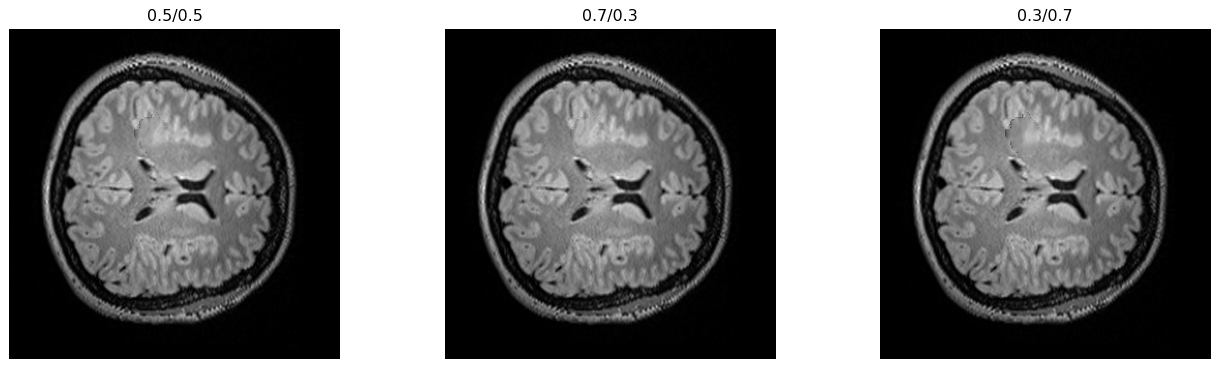

In [11]:
t3=ensure_dir(OUT/"Task 3"); ws=[(0.5,0.5),(0.7,0.3),(0.3,0.7)]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(wa,wb) in zip(axes,ws):
    bl=cv2.addWeighted(a,wa,b,wb,0); save_bgr(t3/f"blend_{wa}_{wb}.jpg",bl)
    ax.imshow(to_rgb(bl)); ax.set_title(f"{wa}/{wb}"); ax.axis("off")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(wa,wb) in zip(axes,ws):
    bl=cv2.addWeighted(a,wa,b,wb,0); ax.imshow(to_rgb(bl)); ax.set_title(f"{wa}/{wb}"); ax.axis("off")
save_fig(t3/"weighted_blends.png")
(t3/"observation.txt").write_text("Blend RESECT before/after.\n",encoding="utf-8")


## Task 4 — subtract / absdiff


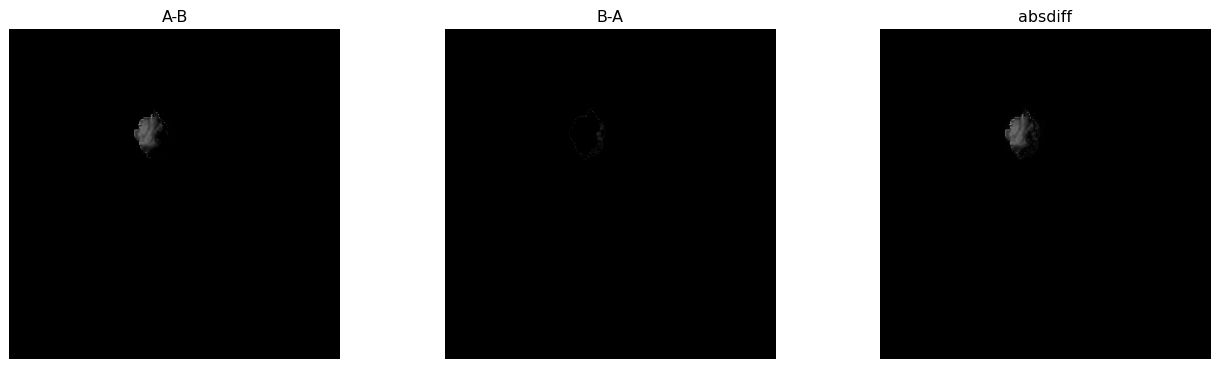

In [13]:
t4=ensure_dir(OUT/"Task 4")
amb,bma,absd=cv2.subtract(a,b),cv2.subtract(b,a),cv2.absdiff(a,b)
save_bgr(t4/"A_minus_B.jpg",amb); save_bgr(t4/"B_minus_A.jpg",bma); save_bgr(t4/"absdiff.jpg",absd)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,im,t in zip(axes,[amb,bma,absd],["A-B","B-A","absdiff"]):
    ax.imshow(to_rgb(im)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,im,t in zip(axes,[amb,bma,absd],["A-B","B-A","absdiff"]):
    ax.imshow(to_rgb(im)); ax.set_title(t); ax.axis("off")
save_fig(t4/"subtraction_compare.png")
(t4/"observation.txt").write_text("absdiff shows tumor change.\n",encoding="utf-8")


## Tasks 5–7 — bitwise


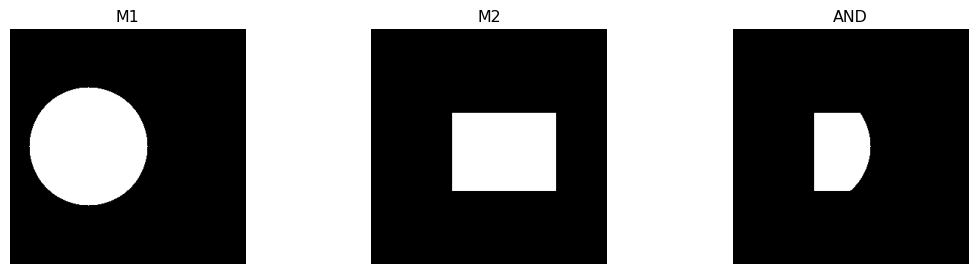

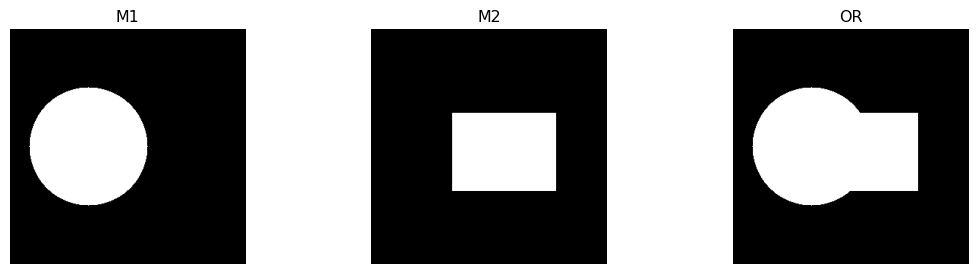

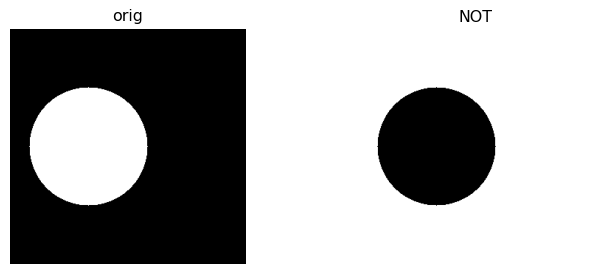

In [15]:
h,w=a.shape[:2]
mask1=np.zeros((h,w),np.uint8); mask2=np.zeros((h,w),np.uint8)
cv2.circle(mask1,(w//3,h//2),min(h,w)//4,255,-1)
cv2.rectangle(mask2,(w//2-50,h//2-45),(w//2+90,h//2+60),255,-1)
t5=ensure_dir(OUT/"Task 5"); bit_and=cv2.bitwise_and(mask1,mask2)
save_bgr(t5/"mask1.jpg",mask1); save_bgr(t5/"mask2.jpg",mask2); save_bgr(t5/"bitwise_and.jpg",bit_and)
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,im,t in zip(axes,[mask1,mask2,bit_and],["M1","M2","AND"]):
    ax.imshow(im,cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show(); save_fig(t5/"bitwise_and.png") if False else None
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,im,t in zip(axes,[mask1,mask2,bit_and],["M1","M2","AND"]):
    ax.imshow(im,cmap="gray"); ax.set_title(t); ax.axis("off")
save_fig(t5/"bitwise_and.png"); (t5/"observation.txt").write_text("AND\n",encoding="utf-8")
t6=ensure_dir(OUT/"Task 6"); bit_or=cv2.bitwise_or(mask1,mask2); save_bgr(t6/"bitwise_or.jpg",bit_or)
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,im,t in zip(axes,[mask1,mask2,bit_or],["M1","M2","OR"]):
    ax.imshow(im,cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,im,t in zip(axes,[mask1,mask2,bit_or],["M1","M2","OR"]):
    ax.imshow(im,cmap="gray"); ax.set_title(t); ax.axis("off")
save_fig(t6/"bitwise_or.png"); (t6/"observation.txt").write_text("OR\n",encoding="utf-8")
t7=ensure_dir(OUT/"Task 7"); bit_not=cv2.bitwise_not(mask1); save_bgr(t7/"bitwise_not.jpg",bit_not)
fig,axes=plt.subplots(1,2,figsize=(8,3))
axes[0].imshow(mask1,cmap="gray"); axes[0].set_title("orig"); axes[0].axis("off")
axes[1].imshow(bit_not,cmap="gray"); axes[1].set_title("NOT"); axes[1].axis("off")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(8,3))
axes[0].imshow(mask1,cmap="gray"); axes[0].set_title("orig"); axes[0].axis("off")
axes[1].imshow(bit_not,cmap="gray"); axes[1].set_title("NOT"); axes[1].axis("off")
save_fig(t7/"bitwise_not.png"); (t7/"observation.txt").write_text("NOT\n",encoding="utf-8")


## Scenario — Tumor change detection on REAL RESECT MRI


Lab 4 done -> C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Output\Lab 4


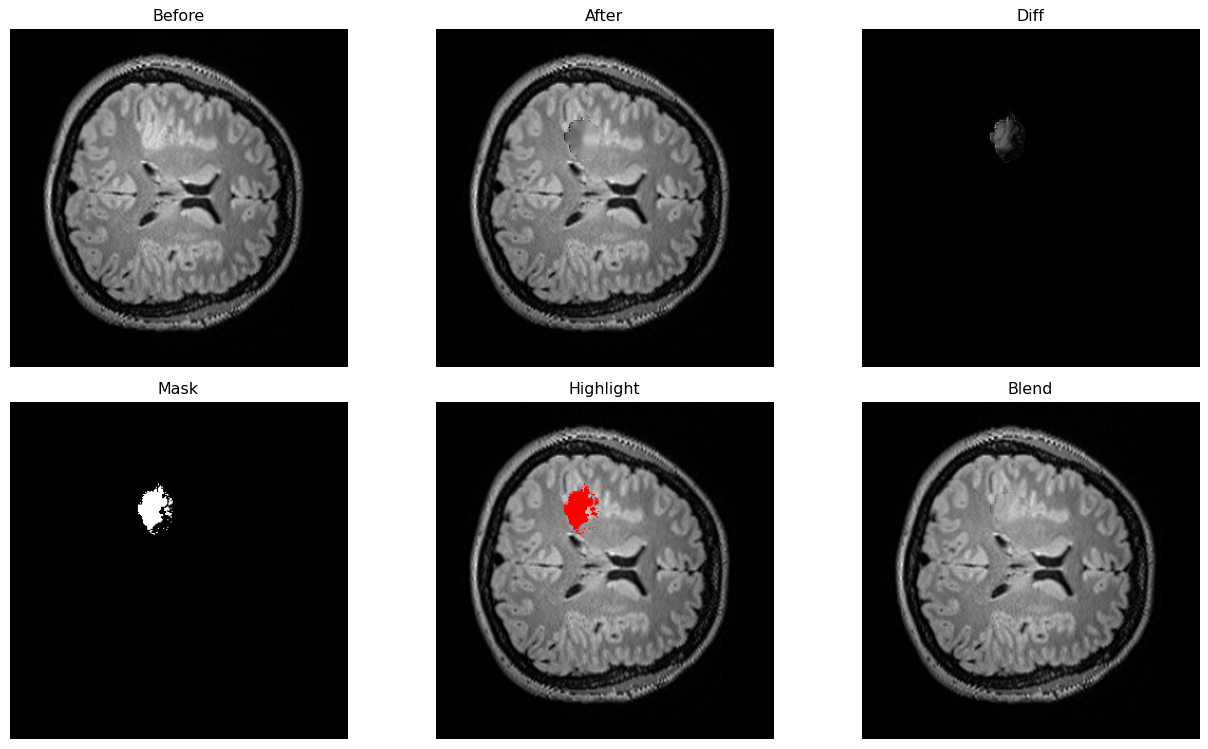

In [17]:
scen=ensure_dir(OUT/"Scenario Change Detection")
change=cv2.absdiff(a,b); g=cv2.cvtColor(change,cv2.COLOR_BGR2GRAY)
_,cm=cv2.threshold(g,15,255,cv2.THRESH_BINARY)
hi=a.copy(); hi[cm>0]=(0,0,255)
blend=cv2.addWeighted(a,0.6,b,0.4,0); roi=cv2.bitwise_and(a,a,mask=cm)
for n,im in [("change_absdiff.jpg",change),("change_mask.jpg",cm),("highlighted_changes.jpg",hi),("blended_compare.jpg",blend),("masked_roi.jpg",roi)]:
    save_bgr(scen/n, im)
panels=[(to_rgb(a),"Before"),(to_rgb(b),"After"),(to_rgb(change),"Diff"),(cm,"Mask"),(to_rgb(hi),"Highlight"),(to_rgb(blend),"Blend")]
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(im,t) in zip(axes.ravel(),panels):
    ax.imshow(im, cmap="gray" if im.ndim==2 else None); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(im,t) in zip(axes.ravel(),panels):
    ax.imshow(im, cmap="gray" if im.ndim==2 else None); ax.set_title(t); ax.axis("off")
save_fig(scen/"scenario_overview.png")
(scen/"observation.txt").write_text(f"RESECT Case1 real FLAIR. Changed%={100*np.mean(cm>0):.2f}\n",encoding="utf-8")
print("Lab 4 done ->", OUT)
